# 1. Single-Series 774 CE Parametric Fit (`Guttler15` + `Miyake12_Cedar`)

This five-cell tutorial replaces the legacy `ticktack 1.x` walkthrough `docs/notebooks/01_Fitting.ipynb`, which fitted the 28-ring Japanese cedar $\Delta^{14}\mathrm{C}$ record of Miyake et al. (2012; `notebooks/miyake12.csv`, 760–787 CE) on the 11-box `Guttler15` carbon-box model using `SingleFitter` and `emcee` (`8` walkers $\times 1000$ steps) in a recorded wall-clock time of **`119.0 s`** (`1 min 59 s`). That `v1` workflow integrated a numerical 2,000-year solar ODE burn-in on every likelihood evaluation, anchored the ambient baseline to the noisy four-ring mean `mean(d14c[:4])`, and sampled polar solar phase directly.

In `ticktack 2.0`, `TreeRingSeries.from_csv` loads whitespace-delimited tables directly alongside standard CSVs, `HarmonicSolar` evaluates the stationary 11-year Schwabe cycle analytically in frequency-domain complex resolvents with zero burn-in integration, and `LinearMarginalConfig` marginalizes both the ambient $\Delta^{14}\mathrm{C}$ baseline and quadrature solar amplitudes `(c_cos, c_sin)` in closed form.

In [1]:
import math, time
import jax, jax.numpy as jnp, numpy as np
import ticktack as tt

cedar = tt.TreeRingSeries.from_csv(
    "notebooks/miyake12.csv", hemisphere="north", growth_season="april-september", name="Miyake12_Cedar"
)
ds = tt.Dataset(cedar, name="Miyake12_774CE")
cbm = tt.load_preset("Guttler15")
prod = tt.ProductionSum(
    steady=tt.SteadyProduction(), solar=tt.HarmonicSolar(periods=11.0, t_ref=775.0),
    spike=tt.MiyakeSpike(t_start=774.5, duration=0.25, fluence=6.5, profile="boxcar"),
)
model = tt.RadiocarbonModel(cbm, prod)
print(f"{cedar.name}: {ds.n_obs} rings ({ds.time_span[0]:.2f}–{ds.time_span[1]:.2f} CE) on {cbm.n_boxes}-box Guttler15")

Miyake12_Cedar: 28 rings (760.25–787.75 CE) on 11-box Guttler15


## Cold and Warm MAP Optimization (`fit_map`)

Because the baseline offset and linear solar quadrature weights are marginalized analytically inside `marginal_log_likelihood`, `ParameterSpace` only needs to parametrize the three nonlinear spike coordinates `(t_start, duration, fluence)`. Below we time both the cold first call – including XLA JIT compilation of the exact [Van Loan (1978)](https://doi.org/10.1109/TAC.1978.1101743) upper-triangular block matrix-exponential propagator (which evaluates forced linear state transitions and ring integrals simultaneously without quadrature error) and `optimistix.BFGS` gradients – and a warm repeat solve from the prior mean.

In [2]:
cfg = tt.LinearMarginalConfig(offset_mode="shared", solar_prior_sd=0.35, marginalize_solar=True)
specs = [
    tt.ParamSpec("production.spike.t_start", "sigmoid", 0.0, 1.2, low=773.5, high=776.0),
    tt.ParamSpec("production.spike.duration", "sigmoid", -0.5, 1.2, low=0.05, high=2.0),
    tt.ParamSpec("production.spike.fluence", "exp", math.log(6.5), 0.5),
]
ps = tt.ParameterSpace(model, specs)
t0 = time.perf_counter()
map_res = tt.fit_map(model, ds, ps, cfg, max_steps=150, rng_key=jax.random.PRNGKey(774))
jax.block_until_ready(map_res.u_map)
dt_map_cold = time.perf_counter() - t0
t1 = time.perf_counter()
map_warm = tt.fit_map(model, ds, ps, cfg, max_steps=150, rng_key=jax.random.PRNGKey(774))
jax.block_until_ready(map_warm.u_map)
print(f"MAP t0={float(map_res.theta_map['production.spike.t_start']):.2f} CE, F={float(map_res.theta_map['production.spike.fluence']):.2f} atoms/cm^2/s*yr | cold={dt_map_cold*1e3:.0f} ms, warm={(time.perf_counter()-t1)*1e3:.1f} ms")

MAP t0=774.73 CE, F=6.36 atoms/cm^2/s*yr | cold=9869 ms, warm=47.2 ms


## Hamiltonian Monte Carlo (`sample_nuts`) vs `v1` `emcee` (`119.0 s`)

Warm-starting `NumPyro` NUTS at the MAP solution with Laplace mass-matrix preconditioning yields well-mixed posterior draws over the 3D nonlinear spike geometry while conditionally drawing exact Gaussian realizations of the ambient baseline, 11-year solar cycle, and continuous $\Delta^{14}\mathrm{C}(t)$ trajectory on a fine temporal grid.

In [3]:
t_fine = jnp.linspace(759.5, 788.5, 291)
t0 = time.perf_counter()
idata = tt.sample_nuts(map_res.model, ds, ps, cfg, num_warmup=150, num_samples=250, num_chains=2, max_tree_depth=6, init_map=False, t_fine=t_fine, rng_key=jax.random.PRNGKey(775))
dt_nuts_cold = time.perf_counter() - t0
t1 = time.perf_counter()
idata_w = tt.sample_nuts(map_res.model, ds, ps, cfg, num_warmup=150, num_samples=250, num_chains=2, max_tree_depth=6, init_map=False, t_fine=t_fine, rng_key=jax.random.PRNGKey(776))
dt_nuts_warm = time.perf_counter() - t1
fl_s = idata.posterior["production__spike__fluence"].values.reshape(-1)
ts_s = idata.posterior["production__spike__t_start"].values.reshape(-1)
v1_sec = 119.0
print(f"NUTS t_start={ts_s.mean():.2f}+/-{ts_s.std():.2f} CE, fluence={fl_s.mean():.2f}+/-{fl_s.std():.2f} atoms/cm^2/s*yr\nTiming vs v1 emcee ({v1_sec:.1f} s): cold={dt_nuts_cold:.2f} s ({v1_sec/dt_nuts_cold:.1f}x), warm={dt_nuts_warm:.2f} s ({v1_sec/dt_nuts_warm:.1f}x)")

NUTS t_start=774.77+/-0.22 CE, fluence=6.34+/-0.30 atoms/cm^2/s*yr
Timing vs v1 emcee (119.0 s): cold=33.00 s (3.6x), warm=11.26 s (10.6x)


## Posterior $\Delta^{14}\mathrm{C}(t)$ Trajectory and Standardized Pulls

Plotting the posterior predictive atmospheric $\Delta^{14}\mathrm{C}(t)$ envelope (`68%` and `95%` credible bands) against the seasonal growth windows `[t_start, t_end]` of the 28 cedar rings confirms that the sharp 774–775 CE rise, stratospheric turnover peak, and post-spike ocean relaxation leave structureless unit-normal pulls $(d - m)/\sigma$.

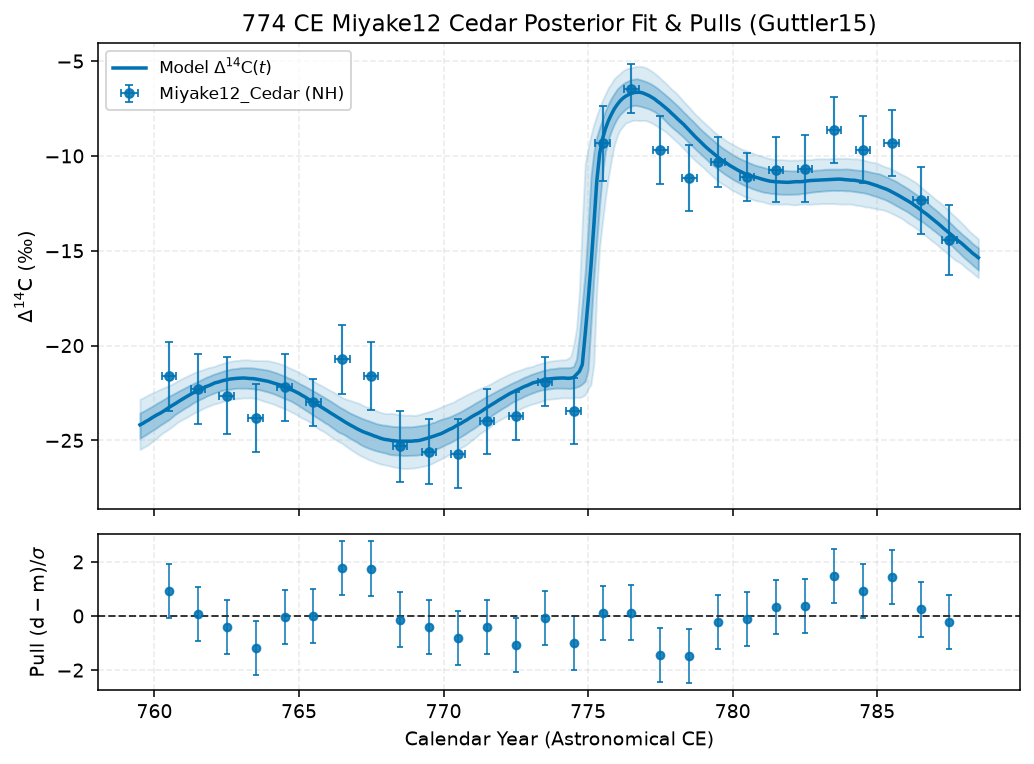

In [4]:
lp_map = tt.linear_posterior(map_res.model, ds, cfg, t_fine=t_fine)
d14c_draws = idata.posterior_predictive["d14c_fine"].values.reshape(-1, t_fine.size)
fig, axes = tt.plot_d14c_fit(
    ds,
    t_fine=t_fine,
    d14c_pred=d14c_draws,
    ring_pred=lp_map.ring_pred_mean,
    show_residuals=True,
    title="774 CE Miyake12 Cedar Posterior Fit & Pulls (Guttler15)",
)

## One-to-One Observed vs Predicted Calibration

As a complementary goodness-of-fit check, `plot_data_model_correlation` compares the observed cedar ring measurements and their $1\sigma$ AMS uncertainties directly against the seasonal-window-binned posterior mean predictions along the `1:1` identity line, annotating the reduced $\chi^2 / N_{\mathrm{obs}}$ and inverse-variance weighted RMS pull.

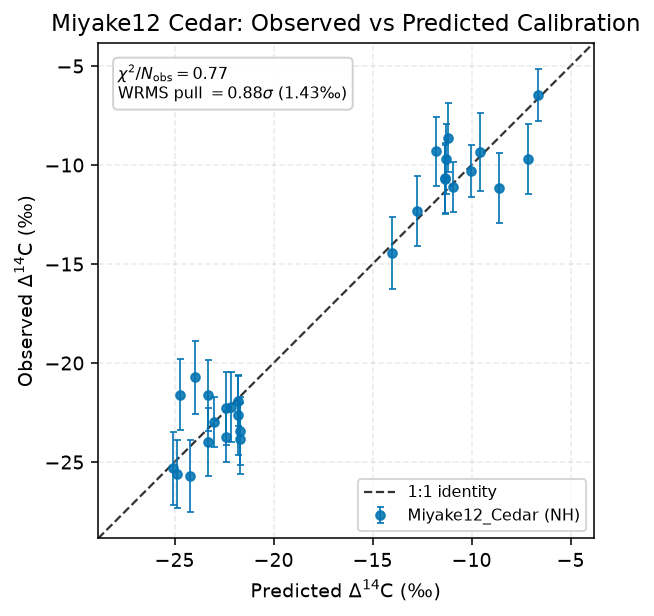

In [5]:
fig_corr, ax_corr = tt.plot_data_model_correlation(
    ds,
    lp_map.ring_pred_mean,
    title="Miyake12 Cedar: Observed vs Predicted Calibration",
)

Replacing numerical ODE burn-in loops and four-point baseline anchoring with exact modal and Van Loan propagation, frequency-domain harmonic resolvents, and analytical Gaussian marginalization accelerates single-series 774 CE Bayesian inference from `119.0 s` in `ticktack 1.x` to `47 ms` warm MAP optimization and `11.3 s` warm two-chain HMC sampling (`10.6x` faster) in `ticktack 2.0` while eliminating boundary and solar-phase biases.